# Tutorial 6: Text mining and RAG preparation

Full text is more than an abstract: methods, results and discussion hold the details. This tutorial uses the raw JATS XML that pubmed-stream can keep, to:

1. Split each article into its sections: introduction, methods, results, discussion.
2. Compare where topics are discussed, section by section.
3. Find the works the corpus cites most often.
4. Cut the text into overlapping chunks with metadata, ready for an embedding model or a retrieval-augmented generation (RAG) pipeline.

Everything uses the Python standard library plus pandas and matplotlib. It takes about a minute.

In [1]:
import json
import re
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tutorial_utils as tu

tu.setup()
tu.style()

from pubmed_stream import search_and_download

## 1. Download with the XML

`fmt="both"` keeps the plain text and the raw JATS XML in each JSON file. The open-access filter guarantees every result can be downloaded.

In [2]:
stats = search_and_download(
    '"gut microbiota"[Title] AND sarcopenia[Title/Abstract] AND "open access"[filter]',
    max_results=10, fmt="both", output_dir="text_mining",
)
articles = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(stats.output_dir.glob("PMC*.json"))]
print(f"{len(articles)} articles with XML")


Found 10 PMC IDs for '"gut microbiota"[Title] AND sarcopenia[Title/Abstract] AND "open access"[filter]' (total PubMed results: 74)
Output directory: text_mining\gut_microbiota_Title_AND_sarcopenia_Title_Abstract_AND_open_access_filter



Progress: 10/10 processed (OK:10 | FAIL:0 | SKIP:0)

Download Summary
Keyword:           "gut microbiota"[Title] AND sarcopenia[Title/Abstract] AND "open access"[filter]
Total found:       74
Requested:         10
[OK] Successful:   10
[FAIL] Failed:     0
  - Unavailable:   0
  - Errors:        0
[SKIP] Skipped:    0
Duration:          4.1s
Output directory:  text_mining\gut_microbiota_Title_AND_sarcopenia_Title_Abstract_AND_open_access_filter


10 articles with XML


## 2. Split articles into sections

JATS marks each top-level section of the body with a `<sec>` element. Its `sec-type` attribute, or else its title, tells which part of the article it is. Reviews have no methods or results, so their sections fall under *Other*.

In [3]:
SECTIONS = ["Introduction", "Methods", "Results", "Discussion", "Other"]
PATTERNS = [
    ("Introduction", r"intro|background"),
    ("Methods", r"method|material|design|participant|patient|statistic"),
    ("Results", r"result|finding"),
    ("Discussion", r"discuss|conclu|limitation|summary"),
]

def section_kind(sec):
    label = f"{sec.get('sec-type', '')} {''.join(sec.findtext('title') or '')}"
    return next((kind for kind, pattern in PATTERNS if re.search(pattern, label, re.I)), "Other")

def sections(xml):
    article = ET.fromstring(xml)
    article = article.find("article") if article.tag != "article" else article
    body = article.find("body")
    parts = []
    for sec in (body.findall("sec") if body is not None else []):
        text = " ".join(" ".join(sec.itertext()).split())
        parts.append({"kind": section_kind(sec), "title": (sec.findtext("title") or "").strip(), "text": text})
    return parts

rows = []
for a in articles:
    for part in sections(a["xml"]):
        rows.append({"pmcid": a["pmcid"], "title": a["metadata"].get("title", ""),
                     "kind": part["kind"], "words": len(part["text"].split()), "text": part["text"]})
sections_df = pd.DataFrame(rows)

words = sections_df.pivot_table(index="pmcid", columns="kind", values="words", aggfunc="sum", fill_value=0)
words = words.reindex(columns=SECTIONS, fill_value=0)
words.assign(total=words.sum(axis=1)).sort_values("total", ascending=False)

kind,Introduction,Methods,Results,Discussion,Other,total
pmcid,,,,,,
PMC13411117,1239,0,0,1750,7557,10546
PMC13618173,377,0,0,298,9758,10433
PMC13595175,1179,206,0,386,7997,9768
PMC13581694,627,1580,3180,1921,0,7308
PMC13402211,885,14,1796,1385,1915,5995
PMC13468338,832,338,0,415,4263,5848
PMC13641649,441,1072,1953,1384,111,4961
PMC13286432,517,467,1056,1542,48,3630


The same table as a chart. Research articles show the classic four-part structure; reviews are mostly *Other*.

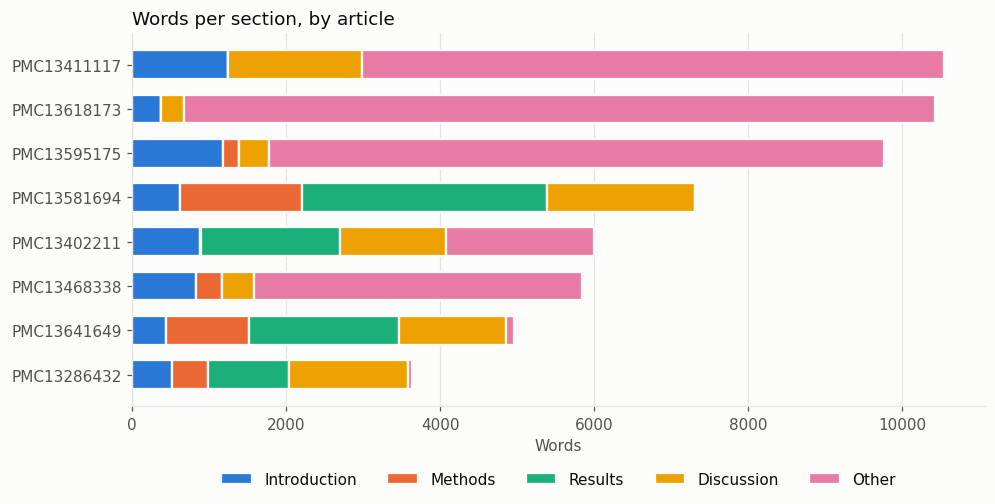

In [4]:
SECTION_COLOURS = dict(zip(SECTIONS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
order = words.sum(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(10, 4.4))
left = np.zeros(len(order))
for kind in SECTIONS:
    values = words.loc[order, kind].values
    ax.barh(order, values, left=left, color=SECTION_COLOURS[kind], edgecolor=tu.SURFACE, lw=1.5, height=0.65, label=kind)
    left += values
tu.gridlines(ax, "x")
ax.set_xlabel("Words")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
ax.set_title("Words per section, by article")
plt.show()

## 3. Where is each topic discussed?

Counting terms per section shows where the corpus discusses them. Mechanisms such as butyrate and inflammation cluster in introductions and discussions, while sequencing and study design sit in the methods. Rates are per 10,000 words, so sections of different length compare fairly.

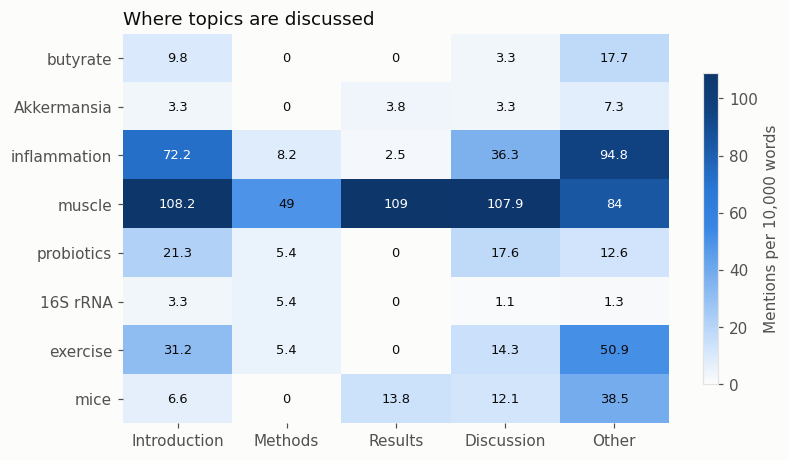

In [5]:
TERMS = {
    "butyrate": r"butyrat", "Akkermansia": r"akkermansia", "inflammation": r"inflamm",
    "muscle": r"\bmuscle", "probiotics": r"probiotic", "16S rRNA": r"16s", "exercise": r"exercis",
    "mice": r"\bmice\b|\bmouse\b",
}
by_kind = sections_df.groupby("kind").agg(text=("text", " ".join), words=("words", "sum")).reindex(SECTIONS).dropna()
rates = pd.DataFrame({
    term: [10000 * len(re.findall(p, t, re.I)) / w for t, w in zip(by_kind.text, by_kind.words)]
    for term, p in TERMS.items()
}, index=by_kind.index).T.round(1)

from matplotlib.colors import LinearSegmentedColormap
fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(rates.values, cmap=LinearSegmentedColormap.from_list("b", [tu.SURFACE] + tu.BLUES), aspect="auto")
ax.set_xticks(range(len(rates.columns)), rates.columns)
ax.set_yticks(range(len(rates.index)), rates.index)
ax.spines[:].set_visible(False)
for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        v = rates.iat[i, j]
        ax.text(j, i, f"{v:g}", ha="center", va="center", fontsize=8.5,
                color="white" if v > rates.values.max() * 0.55 else tu.INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Mentions per 10,000 words")
ax.set_title("Where topics are discussed")
plt.show()

## 4. The works the corpus cites most

Every article's `metadata.references` lists its cited works with a PubMed ID or DOI. Works cited by several articles in the corpus are its shared foundations, and good candidates for a knowledge-graph seed. In this corpus, the review that tutorials 4 and 5 use as their seed, PMID 31319564, is among the most cited.

In [6]:
cited = Counter()
titles = {}
for a in articles:
    seen = set()
    for ref in a["metadata"].get("references", []):
        key = ref.get("pmid") or ref.get("doi")
        if key and key not in seen:
            seen.add(key)
            cited[key] += 1
            titles.setdefault(key, (ref.get("title"), ref.get("year")))
pd.DataFrame([
    {"pmid or doi": k, "cited by": n, "year": titles[k][1], "title": tu.short(titles[k][0] or "", 80)}
    for k, n in cited.most_common(8)
])

,pmid or doi,cited by,year,title
0,31319564,3,2019,"Gut microbiota, muscle mass and function in ag..."
1,36998149,3,2023,Lactobacillus rhamnosus JY02 ameliorates sarco...
2,32066625,3,2020,Mediterranean diet intervention alters the gut...
3,29189738,3,2017,Aging gut microbiota at the cross-road between...
4,34326845,2,2021,Inflammatory bowel diseases and sarcopenia: th...
5,33633246,2,2021,Alterations in intestinal microbiota diversity...
6,39006102,2,2024,Changes in the gut microbiota of patients with...
7,33880058,2,2021,A narrative review of gut-muscle axis and sarc...


## 5. Chunk the text for embeddings or RAG

Embedding models and RAG pipelines work on passages, not whole papers. Each section is cut into chunks of about 200 words that overlap by 40, so a sentence near a boundary keeps its context. Every chunk carries the metadata needed to cite it.

In [7]:
def chunks(text, size=200, overlap=40):
    words = text.split()
    step = size - overlap
    for start in range(0, max(len(words) - overlap, 1), step):
        yield " ".join(words[start:start + size])

meta = {a["pmcid"]: a["metadata"] for a in articles}
records = []
for row in sections_df.itertuples():
    m = meta[row.pmcid]
    for i, passage in enumerate(chunks(row.text)):
        records.append({
            "id": f"{row.pmcid}-{len(records)}",
            "pmcid": row.pmcid, "pmid": m.get("pmid"), "doi": m.get("doi"),
            "title": m.get("title"), "year": m.get("year"), "section": row.kind,
            "text": passage,
        })

with open("chunks.jsonl", "w", encoding="utf-8") as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")
print(f"Wrote {len(records)} chunks to chunks.jsonl. One chunk:\n")
example = dict(records[len(records) // 2])
example["text"] = tu.short(example["text"], 300)
print(json.dumps(example, indent=2, ensure_ascii=False))

Wrote 386 chunks to chunks.jsonl. One chunk:

{
  "id": "PMC13581694-193",
  "pmcid": "PMC13581694",
  "pmid": "42755660",
  "doi": "10.3389/fnut.2026.1942104",
  "title": "Sarcopenia in patients with active ulcerative colitis: associations with serum metabolites and gut microbiota",
  "year": "2026",
  "section": "Results",
  "text": "values, mean, standard deviation, and significant difference indicated by an asterisk above each comparison. 3.3 Correlation analysis between body composition parameters measured by BIA and CT Among the 57 enrolled patients, 44 underwent abdominal CT within one week before or after BIA measurement.…"
}


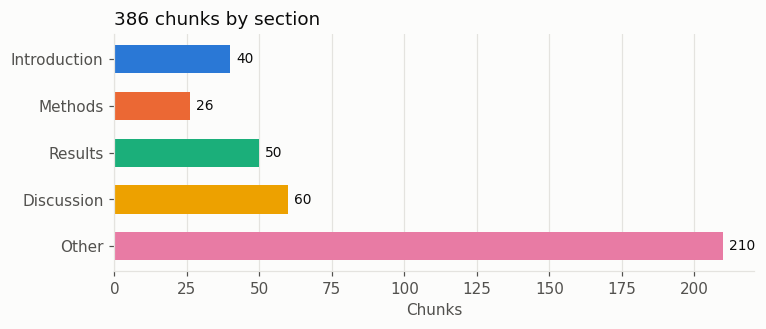

In [8]:
per_section = pd.Series([r["section"] for r in records]).value_counts().reindex(SECTIONS, fill_value=0)
fig, ax = plt.subplots(figsize=(7.5, 2.8))
bars = ax.barh(per_section.index[::-1], per_section.values[::-1],
               color=[SECTION_COLOURS[k] for k in per_section.index[::-1]], height=0.6)
tu.bar_labels(ax, bars, horizontal=True, zero=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Chunks")
ax.set_title(f"{len(records)} chunks by section")
plt.show()

## 6. Next steps

`chunks.jsonl` is the input most embedding and vector-database tools expect. For example, with [Chroma](https://www.trychroma.com/), which is not installed by the tutorials:

```python
import json
import chromadb

collection = chromadb.Client().create_collection("gut_microbiota_sarcopenia")
records = [json.loads(line) for line in open("chunks.jsonl", encoding="utf-8")]
collection.add(
    ids=[r["id"] for r in records],
    documents=[r["text"] for r in records],
    metadatas=[{k: r[k] or "" for k in ("pmcid", "pmid", "title", "year", "section")} for r in records],
)
hits = collection.query(query_texts=["Does butyrate affect muscle mass?"], n_results=5)
```

Keep the `section` field: filtering retrieval to *Results* or *Methods* often answers a question better than searching every chunk.